# Pakistan House Price Predictor: Exploratory Charts

**Notebook 02.** Uses the cleaned data from notebook 01 (`data/cleaned_house_prices.csv`).

Goal: understand what drives house prices in Pakistan before building any model. Each chart answers one question. Under each chart I write what it shows in plain English.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make all charts look clean and readable
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Folder where charts are saved (useful for the README later)
os.makedirs("../images", exist_ok=True)

In [2]:
df = pd.read_csv("../data/cleaned_house_prices.csv")

# Prices have 8 or 9 digits, which is hard to read.
# In Pakistan we say "crore": 1 crore = 10,000,000 PKR.
df["price_crore"] = df["price"] / 10_000_000

print(df.shape)
df.head()

(80351, 17)


,location_id,property_type,price,location,city,province_name,latitude,longitude,baths,bedrooms,date_added,area_marla,year_added,month_added,bedrooms_was_missing,baths_was_missing,price_crore
0,3325,Flat,10000000,G-10,Islamabad,Islamabad Capital,33.679890,73.012640,2,2,2019-02-04,4.0,2019,2,False,False,1.00
1,3236,Flat,6900000,E-11,Islamabad,Islamabad Capital,33.700993,72.971492,3,3,2019-05-04,5.6,2019,5,False,False,0.69
2,764,House,16500000,G-15,Islamabad,Islamabad Capital,33.631486,72.926559,6,5,2019-07-17,8.0,2019,7,False,False,1.65
3,340,House,43500000,Bani Gala,Islamabad,Islamabad Capital,33.707573,73.151199,4,4,2019-04-05,40.0,2019,4,False,False,4.35
4,3226,House,7000000,DHA Defence,Islamabad,Islamabad Capital,33.492591,73.301339,3,3,2019-07-10,8.0,2019,7,False,False,0.70


In [ ]:
df["price_crore"].describe()

## Chart 1: How are prices distributed?

**Question:** Are most houses cheap, expensive, or somewhere in the middle?

A few very expensive houses stretch the normal chart to the right. A **log scale** spreads the prices out so we can see the whole shape. Each step on a log axis multiplies the value (for example 0.1, 1, 10 crore).

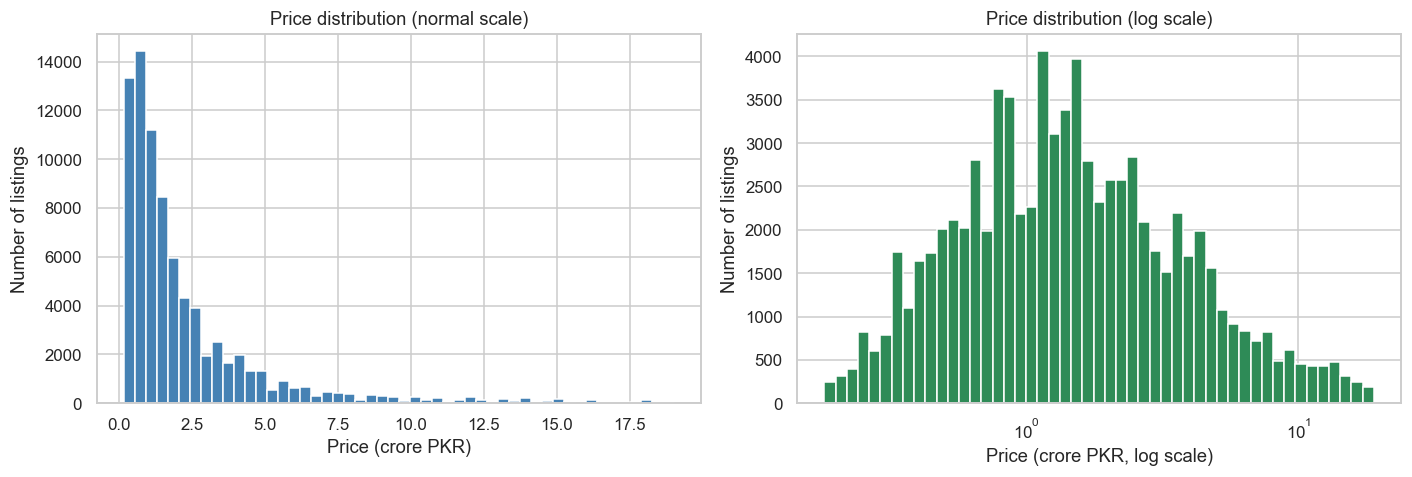

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))   # two charts side by side

# Left: normal scale
axes[0].hist(df["price_crore"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Price distribution (normal scale)")
axes[0].set_xlabel("Price (crore PKR)")
axes[0].set_ylabel("Number of listings")

# Right: log scale. Bin edges are evenly spaced on the log scale.
bins = np.logspace(np.log10(df["price_crore"].min()), np.log10(df["price_crore"].max()), 50)
axes[1].hist(df["price_crore"], bins=bins, color="seagreen", edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Price distribution (log scale)")
axes[1].set_xlabel("Price (crore PKR, log scale)")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
plt.savefig("../images/01_price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 2: Which cities are the most expensive?

**Question:** How much do prices differ between cities?

I show both the **mean** (average) and the **median** (middle value). If the mean is much higher than the median, a few very expensive houses are pulling the average up.

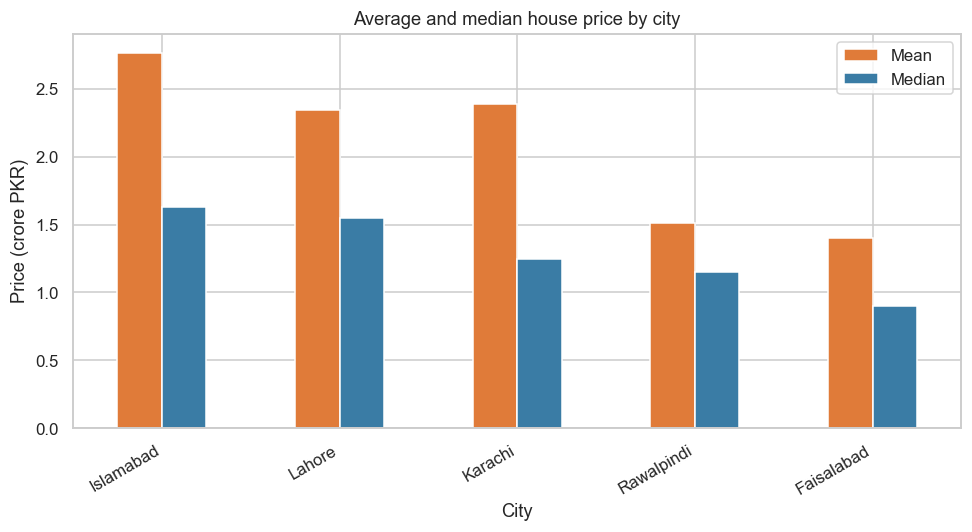

,mean,median
city,,
Islamabad,2.77,1.63
Lahore,2.34,1.55
Karachi,2.39,1.25
Rawalpindi,1.51,1.15
Faisalabad,1.40,0.90


In [4]:
# For each city: the average and the median price, sorted from highest to lowest median
city_prices = (
    df.groupby("city")["price_crore"]
      .agg(["mean", "median"])
      .sort_values("median", ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
city_prices.plot(kind="bar", ax=ax, color=["#e07b39", "#3a7ca5"])
ax.set_title("Average and median house price by city")
ax.set_xlabel("City")
ax.set_ylabel("Price (crore PKR)")
ax.legend(["Mean", "Median"])
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.savefig("../images/02_price_by_city.png", dpi=150, bbox_inches="tight")
plt.show()

city_prices.round(2)

## Chart 3: Does a bigger house cost more?

**Question:** What is the relationship between area (in marla) and price?

Each dot is one listing. Dots are semi-transparent (`alpha`), so places where many houses overlap look darker. Both axes use a log scale because the data is very skewed.

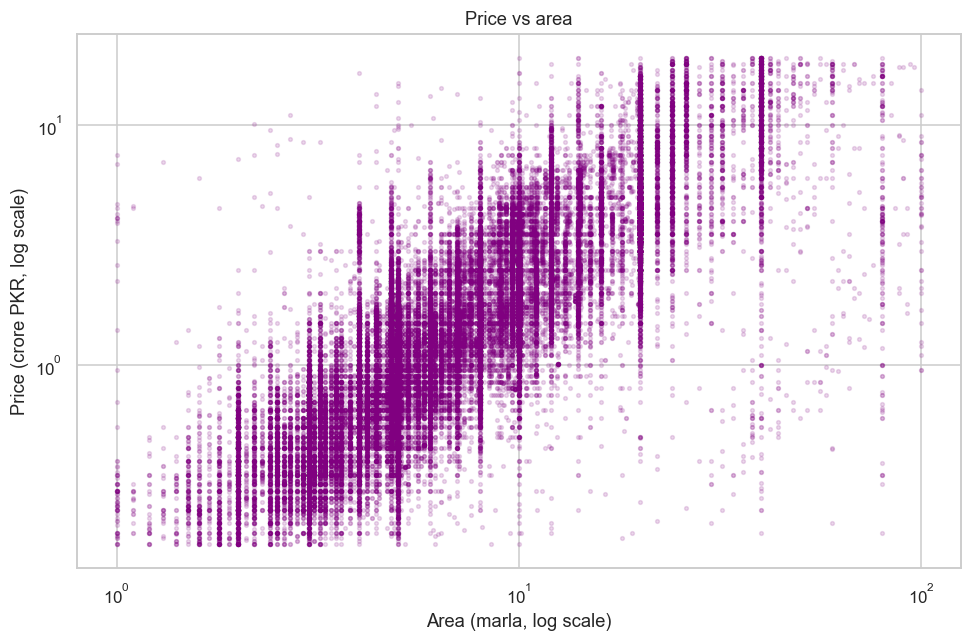

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(df["area_marla"], df["price_crore"], alpha=0.15, s=6, color="purple")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Price vs area")
ax.set_xlabel("Area (marla, log scale)")
ax.set_ylabel("Price (crore PKR, log scale)")

plt.tight_layout()
plt.savefig("../images/03_price_vs_area.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 4: Do more bedrooms mean a higher price?

**Question:** How does the median price change with the number of bedrooms?

I only show bedroom counts with at least 100 listings, because a median from 3 houses is not reliable.

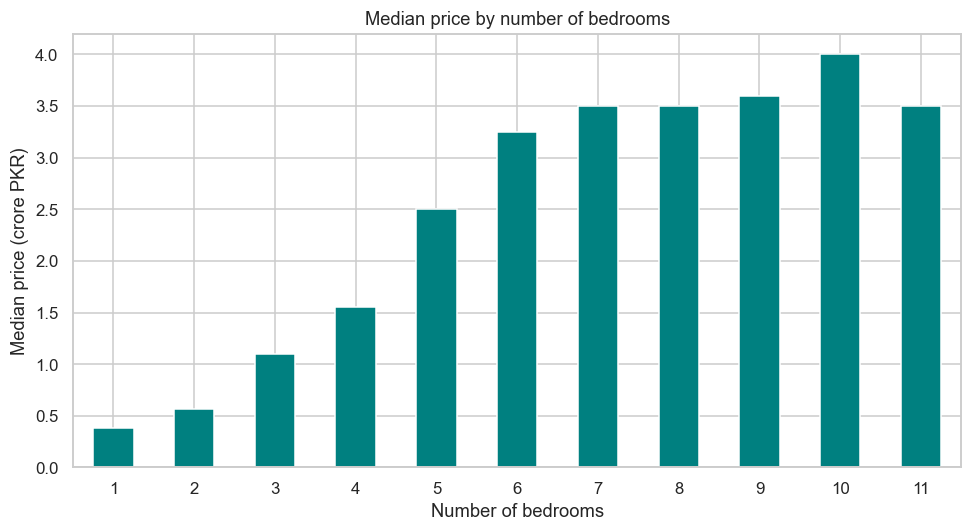

bedrooms
1     0.38
2     0.57
3     1.10
4     1.55
5     2.50
6     3.25
7     3.50
8     3.50
9     3.60
10    4.00
11    3.50
Name: price_crore, dtype: float64

In [6]:
# Keep only bedroom counts that have enough listings
counts = df["bedrooms"].value_counts()
common = counts[counts >= 100].index
subset = df[df["bedrooms"].isin(common)]

bed_prices = subset.groupby("bedrooms")["price_crore"].median()

fig, ax = plt.subplots(figsize=(9, 5))
bed_prices.plot(kind="bar", ax=ax, color="teal")
ax.set_title("Median price by number of bedrooms")
ax.set_xlabel("Number of bedrooms")
ax.set_ylabel("Median price (crore PKR)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("../images/04_price_by_bedrooms.png", dpi=150, bbox_inches="tight")
plt.show()

bed_prices.round(2)

## Chart 5: Which numeric columns are related?

**Question:** Which features move together with price?

A correlation is a number between -1 and +1. Close to +1 means "both go up together", close to 0 means "no relationship", close to -1 means "one goes up while the other goes down". I use **Spearman** correlation because prices are skewed and Spearman handles that better than the default.

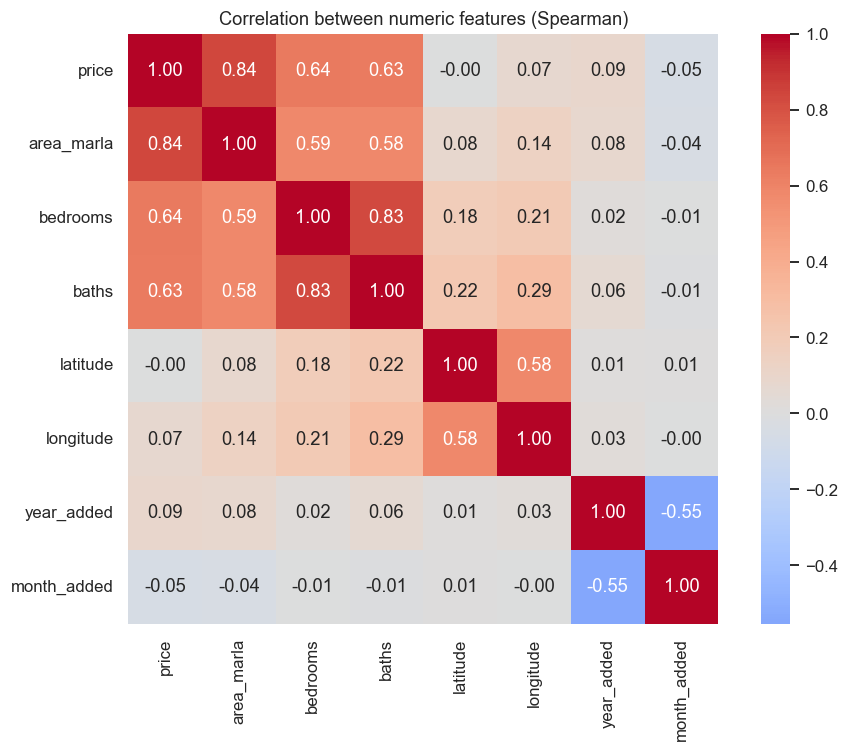

In [7]:
numeric_cols = ["price", "area_marla", "bedrooms", "baths",
                "latitude", "longitude", "year_added", "month_added"]

corr = df[numeric_cols].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between numeric features (Spearman)")

plt.tight_layout()
plt.savefig("../images/05_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 6: Which property types are the most expensive?

**Question:** How does the type of property (House, Flat, Penthouse, and so on) change the price?

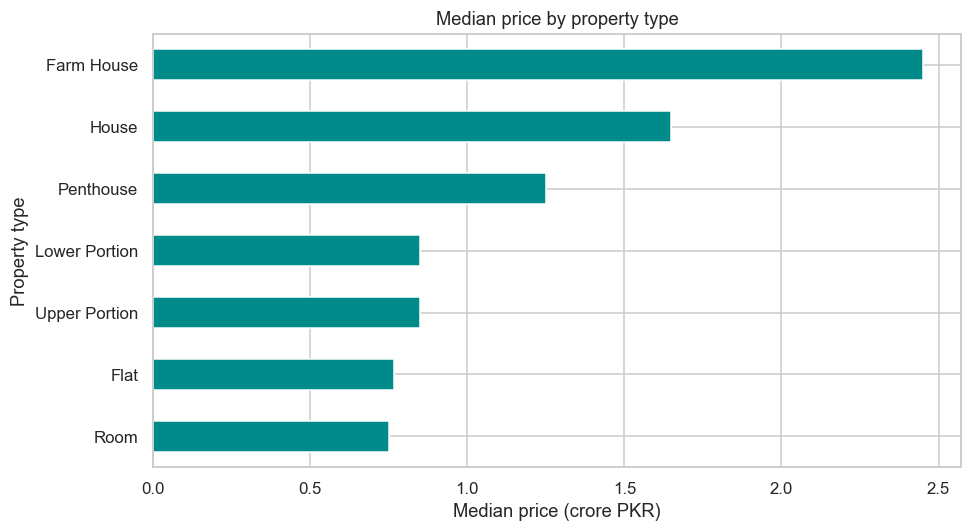

property_type
House            58434
Flat             18765
Upper Portion     1831
Lower Portion      801
Penthouse          269
Farm House         233
Room                18
Name: count, dtype: int64

In [8]:
type_prices = df.groupby("property_type")["price_crore"].median().sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
type_prices.plot(kind="barh", ax=ax, color="darkcyan")
ax.set_title("Median price by property type")
ax.set_xlabel("Median price (crore PKR)")
ax.set_ylabel("Property type")

plt.tight_layout()
plt.savefig("../images/06_price_by_property_type.png", dpi=150, bbox_inches="tight")
plt.show()

# How many listings of each type (so we know how reliable each bar is)
df["property_type"].value_counts()

## Chart 7 (bonus): How many listings were posted each month?

**Question:** Is there a pattern in when listings were posted?

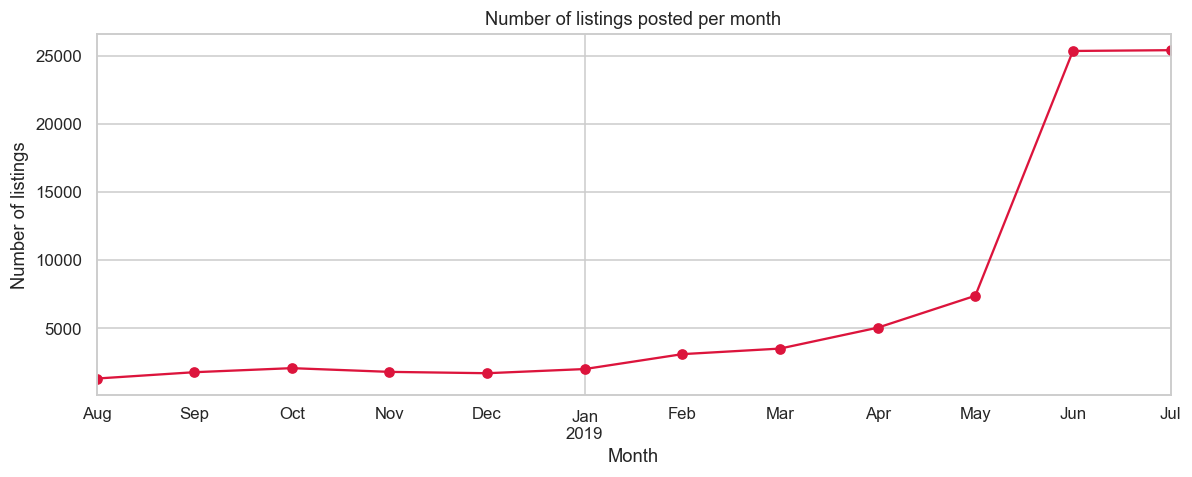

In [9]:
df["date_added"] = pd.to_datetime(df["date_added"])

# Count the listings in each month
monthly = df.groupby(df["date_added"].dt.to_period("M").dt.to_timestamp()).size()

fig, ax = plt.subplots(figsize=(11, 4.5))
monthly.plot(ax=ax, marker="o", color="crimson")
ax.set_title("Number of listings posted per month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of listings")

plt.tight_layout()
plt.savefig("../images/07_listings_per_month.png", dpi=150, bbox_inches="tight")
plt.show()